# Negociação de Pares — Cointegração **Dinâmica** (re-estimação no sinal)

Variante do método de Rad et al. (2016) implementado em `pairs_trading_coint.ipynb`.
A **fase de formação é idêntica**: os pares nomeados e seus parâmetros iniciais vêm do mesmo
`pares_formados_coint.csv`. O que muda é o que acontece **no instante do sinal**.

---

## Motivação

No método estático, $\beta$, $\mu$ e $\sigma$ são estimados na formação e congelados por todo o
período de negociação. Um par pode perder a relação de equilíbrio logo no primeiro mês e ainda
assim ser negociado com um hedge ratio obsoleto até o fim do semestre. É daí que vêm os
*unconverged trades* — a maior fonte de perda da estratégia (36% dos trades na versão estática,
com retorno médio negativo).

A versão dinâmica trata a nomeação do par como **candidatura**, não como licença de negociação:

> No dia em que o z-score cruza $\pm\delta$, o par é **re-testado** com toda a informação
> disponível até aquele dia — o período de formação inteiro **mais** o trecho já decorrido da
> negociação. Se a cointegração não sobreviver, o trade não é aberto: a relação se perdeu.
> Se sobreviver, o trade é aberto com os parâmetros **re-estimados**, não com os da formação.

---

## Os três papéis, separados

| Etapa | Quem decide | Parâmetros usados |
|---|---|---|
| **Quando** há sinal | z-score de monitoramento | $\beta,\mu,\sigma$ **da formação** (fixos) |
| **Se** o trade abre | re-teste de cointegração + z reconfirmado | amostra até o dia do sinal |
| **Como** o trade corre e fecha | spread re-definido | $\beta,\alpha,\mu,\sigma$ **re-estimados** |

Manter o monitoramento nos parâmetros da formação é deliberado: a **regra** que gera sinais é
exatamente a da versão estática, de modo que nenhuma diferença de resultado vem de um gatilho
recalibrado — vem do filtro de revalidação e do hedge ratio atualizado.

Isso **não** implica que os dois notebooks observem o mesmo número de sinais. Um sinal só é
observável com o par fora do mercado, e o estado depende das decisões dinâmicas. Dois efeitos
opostos atuam:

- **vetos aumentam a contagem** — um sinal recusado devolve o par ao monitoramento, e ele volta
  a cruzar a banda; na versão estática aquele mesmo par estaria posicionado, sem gerar sinal;
- **trades mais longos reduzem a contagem** — fechando por $z_{novo} \to 0$ em vez de
  $z_{form} \to 0$, um trade pode durar mais e engolir um cruzamento que na versão estática
  teria virado um segundo trade.

A comparação legítima entre as duas versões é a de **desempenho** (seção 10), não a de contagem
bruta de sinais.

---

## Sem look-ahead

A re-estimação no dia $t$ usa dados até $t$ **inclusive**, e a posição resultante só produz P&L
a partir de $t+1$ — o mesmo lag de execução da versão estática (`position_lag`). A amostra
nunca contém informação posterior à decisão.

---

## O que muda em relação ao notebook estático

| | Estático | Dinâmico |
|---|---|---|
| Pares nomeados | formação | formação (idêntico) |
| $\beta,\alpha,\mu,\sigma$ | fixos o período todo | re-estimados a cada abertura |
| Teste de cointegração | só na formação | formação + revalidação em cada sinal |
| Sinal reprovado | não existe | trade vetado; par segue monitorado |
| Definição do spread | uma por período | uma por trade |

## 1. Setup

In [19]:
import time
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller
from statsmodels.stats.stattools import durbin_watson

warnings.filterwarnings('ignore')

# === Parâmetros da estratégia (idênticos ao notebook estático) ===
DELTA     = 2.0    # gatilho de entrada: abre posição quando |z| > DELTA
STOP      = None   # Rad et al. não usa stop-loss — posições fecham por z→0 ou fim do período
# ⚠️ PADRONIZADO em 2026-09-22: era 0.005, igualado ao da distância.
SIGMA_MIN = 0.01   # exclui pares com sigma patológico (ghost tickers ~ 0.00002)

# Guarda numérica para o dimensionamento 1/β de Rad et al. (§4.2.2): quando z > +δ a regra é
# "short 1/β do dependente, long $1 do independente". Com β ≤ 0 a posição perde sentido
# econômico e com β → 0 o fator 1/β explode. Aplicada tanto ao β da formação quanto ao
# β re-estimado no sinal.
BETA_MIN  = 0.05

# === Filtro de qualidade de dados ===
MAX_RETORNO_DIA = 0.90   # spike positivo extremo = corrupção de dados. None = sem filtro.

# === Convenção do portfólio (série DIÁRIA agregada) ===
COMMITTED_CAPITAL = True   # True → denominador = N pares fixo (pares inativos contribuem 0)

# === Retorno MENSAL (Rad et al., §4.5, eq. 14 e 15) ===
N_PARES_NOMINADOS = 20   # N_P da eq. (15)

# === Filtro de período (mês no formato 'YYYY-MM') ===
PERIODO_INICIO = None   # ex: '1992-01'
PERIODO_FIM    = '2015-12'   # ex: '2020-12'

META_COLS = ['year', 'semester', 'period', 'day_in_semester', 'total_days_sem']


# ══════════════════════════════════════════════════════════════════════════════
#  RE-ESTIMAÇÃO DINÂMICA — o que distingue este notebook
# ══════════════════════════════════════════════════════════════════════════════

# Amostra usada na re-estimação, sempre terminando no dia do sinal:
#   None → EXPANDING: desde o primeiro dia do período de FORMAÇÃO. A amostra cresce ao
#          longo da negociação (T ≈ 252 no primeiro dia de negociação → ≈ 378 no último).
#   int  → ROLLING: os últimos N pregões (ex.: 252 ≈ 12 meses). Amostra de tamanho
#          constante, mais reativa a quebras de relação, porém com mais ruído.
JANELA_REESTIMACAO = None

# Quando re-testar, estando fora do mercado:
#   'cruzamento' → apenas no dia em que |z| atravessa δ vindo de dentro da banda. Reprovado,
#                  o par só é testado de novo no próximo cruzamento.
#   'diario'     → todo dia em que |z| > δ. Dá mais chances (um par reprovado hoje pode
#                  passar amanhã, com um dia a mais de amostra), mas é bem mais lento.
RETESTE_MODO = 'cruzamento'

# Teste aplicado na revalidação — default: o mesmo critério que qualificou o par na formação.
# Critério de seleção de defasagens do ADF: "AIC" ou "BIC".
# O BIC penaliza mais parâmetros, então escolhe menos lags — testa-se
# o efeito disso na seleção e no re-teste.
AUTOLAG_ADF = "AIC"

METODO_COINT_RETESTE = "ADF"    # "ADF" (MacKinnon) ou "CRDW" (Engle-Granger 1987)
BILATERAL_RETESTE    = True     # True  → as duas direções precisam passar (igual à formação)
                                # False → só a direção salva no CSV da formação
                                # A direção do trade é SEMPRE a da formação: o par não troca
                                # de orientação no meio do período.

CRIT_COINT_5PCT    = -3.34  # ADF: MacKinnon 5% para resíduo de regressão de cointegração
CRDW_CRIT_REF_T100 = 0.386  # CRDW: crítico de tabela para T≈100, reescalado por 100/T
                            # (ver crit_crdw — a distribuição nula do CRDW escala com 1/T)

# Dupla confirmação: além de passar no teste, exige |z| > DELTA recalculado com os parâmetros
# NOVOS. Decidir a entrada com os mesmos parâmetros que vão governar o trade. Desligar isola
# o efeito puro do filtro de cointegração.
EXIGE_Z_REESTIMADO = False

## 2. Carregando os dados

In [20]:
pares_raw = pd.read_csv('output/pares/pares_formados_coint.csv')
df        = pd.read_csv('../../data_bases/base_unificada.csv', parse_dates=['date'])
df        = df.set_index('date')

# Compatibilidade com arquivos antigos (antes do teste bilateral / CRDW):
#   - 'adf_stat' virou 'stat' (genérico: ADF ou CRDW)
#   - 'direcao' indica a orientação do OLS salvo; arquivos antigos eram sempre 'B~A'
if 'stat' not in pares_raw.columns and 'adf_stat' in pares_raw.columns:
    pares_raw = pares_raw.rename(columns={'adf_stat': 'stat'})
if 'direcao' not in pares_raw.columns:
    pares_raw['direcao'] = 'B~A'

colunas_preco    = [c for c in df.columns if c not in META_COLS]
meses_por_linha  = pd.PeriodIndex(df.index, freq='M')

# Filtro de período sobre o início do semestre de negociação
pares = pares_raw.copy()
if PERIODO_INICIO is not None:
    pares = pares[pares['negociacao_inicio'] >= PERIODO_INICIO]
if PERIODO_FIM is not None:
    pares = pares[pares['negociacao_fim'] <= PERIODO_FIM]

metodo_arquivo = pares_raw['metodo'].iloc[0] if 'metodo' in pares_raw.columns else 'ADF'
print(f"Pares disponíveis : {len(pares_raw):,} ({pares_raw['janela'].nunique()} janelas)")
print(f"Teste na formação : {metodo_arquivo} | bilateral (ambas as direções)")
if PERIODO_INICIO or PERIODO_FIM:
    ini = PERIODO_INICIO or pares_raw['negociacao_inicio'].min()
    fim = PERIODO_FIM    or pares_raw['negociacao_fim'].max()
    print(f"Período filtrado  : {ini} → {fim}  ({len(pares):,} pares, {pares['janela'].nunique()} janelas)")
else:
    print("Período filtrado  : todo o histórico")
print(f"Base de preços    : {df.shape[0]:,} dias × {len(colunas_preco):,} tickers")

Pares disponíveis : 8,139 (409 janelas)
Teste na formação : ADF | bilateral (ambas as direções)
Período filtrado  : 1991-07 → 2015-12  (5,768 pares, 289 janelas)
Base de preços    : 8,940 dias × 1,343 tickers


## 3. Lógica de negociação

### Direção do spread

A coluna `direcao` (salva na formação) diz qual ativo é a variável **dependente** do OLS:

- `direcao == 'B~A'` → `dep = ativo2`, `indep = ativo1`
- `direcao == 'A~B'` → `dep = ativo1`, `indep = ativo2`

O spread é sempre $\text{spread}_t = Q_{dep}(t) - \alpha - \beta \cdot Q_{indep}(t)$, e a
**direção é preservada na re-estimação** — o par mantém sua identidade do começo ao fim do
período. Trocá-la no meio tornaria o P&L incomparável dentro da mesma janela.

### Normalização

Todo $Q$ é normalizado pelo **primeiro preço do período de formação**, tanto na formação
quanto na negociação. Isso vale também para as amostras de re-estimação: mantendo a mesma
base, o $\beta$ re-estimado é diretamente comparável ao $\beta$ da formação.

### Máquina de estados

```
                       ┌──────────────────────────────────────┐
                       │  FORA DO MERCADO                     │
                       │  monitora z com β,μ,σ da FORMAÇÃO    │
                       └──────────────┬───────────────────────┘
                                      │  |z_monitor| cruza ±δ
                                      ▼
                       ┌──────────────────────────────────────┐
                       │  RE-ESTIMA sobre [amostra … dia t]   │
                       │  OLS  →  ADF / CRDW                  │
                       └──────────────┬───────────────────────┘
                    reprova           │           aprova
              ┌───────────────────────┴───────────────────────┐
              ▼                                               ▼
   ┌─────────────────────┐                    ┌──────────────────────────────┐
   │ trade VETADO        │                    │ |z_novo| > δ ?               │
   │ volta a monitorar   │◄───── não ─────────┤ (dupla confirmação)          │
   └─────────────────────┘                    └──────────────┬───────────────┘
                                                             │ sim
                                                             ▼
                       ┌──────────────────────────────────────────────────┐
                       │  POSICIONADO — spread redefinido por α,β novos   │
                       │  fecha quando z_novo → 0  ou  fim do período     │
                       └──────────────────────────────────────────────────┘
```

### Retorno

Idêntico à versão estática, mas com o $\beta$ do trade vigente:

$$r_t = \begin{cases}
+\Delta\text{spread}_t & \text{position} = -1 \quad (\text{long \$1 em } Q_{dep}) \\[4pt]
-\Delta\text{spread}_t / \beta & \text{position} = +1 \quad (\text{long \$1 em } Q_{indep})
\end{cases}$$

O denominador é sempre a perna comprada de \$1 (Rad et al., §5.1). Como cada trade tem sua
própria definição de spread, $\Delta\text{spread}$ é acumulado **dentro** do trade — nunca
atravessando uma re-definição, o que produziria um salto artificial de P&L.

## 4. Funções

In [21]:
# ══════════════════════════════════════════════════════════════════════════════
#  Teste de cointegração — mesmas rotinas de pairs_formation_coint.ipynb
# ══════════════════════════════════════════════════════════════════════════════

def _ols_residuo(y_arr, x_arr):
    """OLS com intercepto: y = alpha + beta·x + resíduo. Retorna (alpha, beta, resíduo)."""
    X      = sm.add_constant(np.asarray(x_arr, dtype=float), has_constant='add')
    model  = sm.OLS(np.asarray(y_arr, dtype=float), X).fit()
    params = np.asarray(model.params)          # [constante, coef_x]
    return float(params[0]), float(params[1]), model.resid


def crit_crdw(T):
    """
    Valor crítico do CRDW a 5%, reescalado para o tamanho de amostra T.
    crit(T) = CRDW_CRIT_REF_T100 × 100 / T   (a distribuição nula do CRDW ~ O(1/T)).
    Relevante aqui: no modo EXPANDING o T cresce ao longo da negociação, então o critério
    precisa acompanhar — um valor fixo mudaria de severidade ao longo do período.
    """
    return CRDW_CRIT_REF_T100 * 100.0 / T


def _estatistica_residuo(residuo, metodo):
    """
    ADF  — regression='n': o resíduo do OLS com intercepto já tem média zero por construção,
           que é a especificação consistente com o crítico de MacKinnon (−3.34).
           Mais negativo = mais estacionário → passa se stat < CRIT_COINT_5PCT.
    CRDW — DW ≈ 2·(1 − ρ): resíduo estacionário → DW longe de zero.
           Maior = mais estacionário → passa se stat > crit_crdw(T).
    """
    if metodo == "ADF":
        stat   = adfuller(residuo, autolag=AUTOLAG_ADF, regression='n')[0]
        passou = stat < CRIT_COINT_5PCT
    elif metodo == "CRDW":
        stat   = durbin_watson(residuo)
        passou = stat > crit_crdw(len(residuo))
    else:
        raise ValueError(f"Método de cointegração desconhecido: {metodo!r} (use 'ADF' ou 'CRDW')")
    return float(stat), bool(passou)


def reestimar_par(q_dep, q_ind, metodo=None, bilateral=None):
    """
    Re-estima a relação de cointegração de um par sobre a amostra fornecida.

    Diferença essencial em relação a `testar_cointegracao` da formação: aqui a orientação
    (dependente/independente) é **imposta pelo chamador** — é a direção fixada na formação.
    Na formação a orientação era escolhida (a mais estacionária das duas); aqui ela já faz
    parte da identidade do par, e trocá-la no meio do período tornaria o P&L incomparável.

    q_dep, q_ind : arrays Q já orientados (dependente e independente do OLS).
    bilateral    : se True, a direção inversa também precisa passar no teste — replicando
                   o critério de aprovação usado na formação.

    Retorna dict: cointegrado, alpha, beta, mu, sigma, stat.
    """
    if metodo    is None: metodo    = METODO_COINT_RETESTE
    if bilateral is None: bilateral = BILATERAL_RETESTE

    falha = {'cointegrado': False, 'alpha': np.nan, 'beta': np.nan,
             'mu': np.nan, 'sigma': np.nan, 'stat': np.nan}

    q_dep = np.asarray(q_dep, dtype=float)
    q_ind = np.asarray(q_ind, dtype=float)

    # Amostra curta ou série degenerada → regressão sem sentido
    if len(q_dep) < 30 or q_dep.std() < 1e-10 or q_ind.std() < 1e-10:
        return falha

    alpha, beta, resid = _ols_residuo(q_dep, q_ind)
    stat, passou       = _estatistica_residuo(resid, metodo)

    if passou and bilateral:
        _, _, resid_inv = _ols_residuo(q_ind, q_dep)
        _, passou_inv   = _estatistica_residuo(resid_inv, metodo)
        passou          = passou and passou_inv

    if not passou:
        return {**falha, 'stat': stat}

    return {'cointegrado': True, 'alpha': alpha, 'beta': beta,
            'mu': float(resid.mean()), 'sigma': float(resid.std()), 'stat': stat}


# ══════════════════════════════════════════════════════════════════════════════
#  Simulação de um par com re-estimação no sinal
# ══════════════════════════════════════════════════════════════════════════════

def simular_par_coint_dinamico(precos_form, precos_neg, alpha, beta, mu, sigma,
                               direcao='B~A', delta=None, stop=None,
                               janela=None, modo=None,
                               metodo=None, bilateral=None, exige_z=None):
    """
    Simula a negociação de um par revalidando a cointegração no instante de cada sinal.

    precos_form : DataFrame (T × 2) com preços no período de formação [ativo1, ativo2]
    precos_neg  : DataFrame (τ × 2) com preços no período de negociação [ativo1, ativo2]
    alpha..sigma: parâmetros da FORMAÇÃO — usados no z-score de monitoramento
    direcao     : orientação do OLS salva na formação ('B~A' ou 'A~B')

    Convenção de sinal (idêntica à versão estática):
      position = +1  →  z > +δ: spread alto  → vende o spread
                        (LONG $1 em Q_indep, SHORT $1/β em Q_dep)
      position = -1  →  z < -δ: spread baixo → compra o spread
                        (LONG $1 em Q_dep, SHORT $β em Q_indep)

    Retorna (df, info), ou (None, None) se o par não puder ser simulado.
      df   : índice = dias de negociação; colunas z_monitor, z_trade, beta_vigente,
             position, position_lag, retorno_diario
      info : contadores de sinais/vetos + log de eventos por sinal
    """
    if delta   is None: delta   = DELTA
    if stop    is None: stop    = STOP
    if janela  is None: janela  = JANELA_REESTIMACAO
    if modo    is None: modo    = RETESTE_MODO
    if exige_z is None: exige_z = EXIGE_Z_REESTIMADO

    # Parâmetros da formação inviáveis → o monitoramento sequer é definível
    if sigma == 0 or not np.isfinite(beta) or beta <= 0:
        return None, None

    a1, a2     = precos_form.columns[0], precos_form.columns[1]
    dep, indep = (a1, a2) if direcao == 'A~B' else (a2, a1)

    precos_form = precos_form.sort_index()
    precos_neg  = precos_neg.sort_index()

    # Série contínua formação + negociação, normalizada pelo 1º preço da FORMAÇÃO — a mesma
    # base do OLS original, o que torna o β re-estimado comparável ao β da formação.
    Q_all = pd.concat([precos_form, precos_neg]).div(precos_form.iloc[0])
    Q_all = Q_all[~Q_all.index.duplicated(keep='first')].sort_index()

    q_dep = Q_all[dep].values
    q_ind = Q_all[indep].values

    # Posições dos dias de negociação dentro da série contínua
    g_neg = Q_all.index.get_indexer(precos_neg.index)
    g_neg = g_neg[g_neg >= 0]
    if len(g_neg) == 0:
        return None, None
    n = len(g_neg)

    # z de MONITORAMENTO: parâmetros congelados da formação, idêntico ao notebook estático.
    # Define QUANDO há sinal; o re-teste define SE o trade acontece.
    z_mon = ((q_dep[g_neg] - alpha - beta * q_ind[g_neg]) - mu) / sigma

    positions     = np.zeros(n)
    positions_lag = np.zeros(n)
    retorno       = np.zeros(n)
    z_trade       = np.full(n, np.nan)   # z na definição vigente (NaN fora do mercado)
    beta_vigente  = np.full(n, np.nan)

    pos     = 0          # posição herdada do dia anterior
    par_viv = None       # parâmetros do trade em curso
    s_ant   = np.nan     # spread do dia anterior, na definição vigente
    z_hoje  = np.nan

    eventos  = []
    n_sinais = n_aprov = n_rej_coint = n_rej_z = n_rej_beta = 0
    betas_abertura = []

    for k in range(n):
        g = g_neg[k]
        positions_lag[k] = pos

        # ── P&L do dia k: variação do spread na definição do trade vigente ────────────
        if pos != 0:
            s_hoje          = q_dep[g] - par_viv['alpha'] - par_viv['beta'] * q_ind[g]
            escala          = 1.0 / par_viv['beta'] if pos > 0 else 1.0
            retorno[k]      = -pos * escala * (s_hoje - s_ant)
            z_hoje          = (s_hoje - par_viv['mu']) / par_viv['sigma']
            s_ant           = s_hoje
            z_trade[k]      = z_hoje
            beta_vigente[k] = par_viv['beta']

        if pos == 0:
            # ── Fora do mercado: há sinal? ───────────────────────────────────────────
            acima = abs(z_mon[k]) > delta
            if modo == 'cruzamento':
                gatilho = acima and (k == 0 or abs(z_mon[k - 1]) <= delta)
            else:                                    # 'diario'
                gatilho = acima

            if gatilho:
                n_sinais += 1
                ini  = 0 if janela is None else max(0, g + 1 - janela)
                novo = reestimar_par(q_dep[ini:g + 1], q_ind[ini:g + 1],
                                     metodo=metodo, bilateral=bilateral)

                z_novo = np.nan
                if not novo['cointegrado']:
                    n_rej_coint += 1
                    motivo = 'sem_cointegracao'
                elif (not np.isfinite(novo['beta']) or novo['beta'] < BETA_MIN
                      or novo['sigma'] < SIGMA_MIN):
                    n_rej_beta += 1
                    motivo = 'beta_ou_sigma'
                else:
                    s_novo = q_dep[g] - novo['alpha'] - novo['beta'] * q_ind[g]
                    z_novo = (s_novo - novo['mu']) / novo['sigma']
                    if exige_z and abs(z_novo) <= delta:
                        n_rej_z += 1
                        motivo = 'z_reestimado_dentro_da_banda'
                    else:
                        # Abre com os parâmetros NOVOS. A direção vem do z re-estimado —
                        # é ele que governa o trade daqui em diante.
                        pos             = +1 if z_novo > 0 else -1
                        par_viv         = novo
                        s_ant           = s_novo
                        z_trade[k]      = z_novo
                        beta_vigente[k] = novo['beta']
                        n_aprov        += 1
                        betas_abertura.append(novo['beta'])
                        motivo = 'aprovado'

                eventos.append({
                    'data':      Q_all.index[g],
                    'motivo':    motivo,
                    'n_amostra': int(g + 1 - ini),
                    'z_monitor': float(z_mon[k]),
                    'z_novo':    float(z_novo) if np.isfinite(z_novo) else np.nan,
                    'stat_novo': novo['stat'],
                    'beta_novo': novo['beta'],
                })
        else:
            # ── Posicionado: regras de saída, com os parâmetros DO TRADE ─────────────
            if stop is not None and abs(z_hoje) > stop:
                pos, par_viv, s_ant = 0, None, np.nan     # stop-loss
            elif pos == +1 and z_hoje <= 0:
                pos, par_viv, s_ant = 0, None, np.nan     # reverteu à média
            elif pos == -1 and z_hoje >= 0:
                pos, par_viv, s_ant = 0, None, np.nan     # reverteu à média

        positions[k] = pos

    df = pd.DataFrame({
        'z_monitor':      z_mon,
        'z_trade':        z_trade,
        'beta_vigente':   beta_vigente,
        'position':       positions,
        'position_lag':   positions_lag,
        'retorno_diario': retorno,
    }, index=Q_all.index[g_neg])

    info = {
        'n_sinais':    n_sinais,
        'n_aprovados': n_aprov,
        'n_rej_coint': n_rej_coint,
        'n_rej_z':     n_rej_z,
        'n_rej_beta':  n_rej_beta,
        'beta_medio':  float(np.mean(betas_abertura)) if betas_abertura else np.nan,
        'eventos':     eventos,
    }
    return df, info


def contar_trades(positions):
    """Retorna (n_abertos, n_fechados_normal, n_forcados)."""
    pos = np.asarray(positions)
    entradas = np.sum((pos[1:] != 0) & (pos[:-1] == 0))
    if pos[0] != 0:
        entradas += 1
    saidas_normais = np.sum((pos[:-1] != 0) & (pos[1:] == 0))
    forcado        = 1 if pos[-1] != 0 else 0
    return int(entradas), int(saidas_normais), int(forcado)

## 5. Simulação completa

Os **cinco filtros de exclusão** da versão estática continuam valendo, aplicados aos
parâmetros da formação antes de o par entrar na simulação:

1. `sigma < SIGMA_MIN` — ghost tickers com sigma ~ 0
2. `beta < BETA_MIN` — dimensionamento 1/β degenerado
3. ticker ausente da base de preços
4. sem dados na formação ou na negociação
5. `MAX_RETORNO_DIA` — spike positivo extremo (corrupção de dados)

A eles soma-se o filtro dinâmico, aplicado **dentro** da simulação, sinal a sinal: o par entra
normalmente e é o re-teste que decide cada abertura.

> ⏱️ Este notebook é bem mais pesado que o estático: cada sinal dispara um OLS + ADF
> (dobrado com `BILATERAL_RETESTE = True`). Com `RETESTE_MODO = 'cruzamento'` espere alguns
> minutos; com `'diario'`, bem mais.

In [22]:
t_inicio = time.time()

resultados_pares  = []
retornos_por_data = {}
registros_mensais = []   # (janela, mes, par) → retorno mensal marcado a mercado + flag negociou
eventos_log       = []   # um registro por SINAL avaliado (aprovado ou vetado)

n_skip_sigma   = 0
n_skip_beta    = 0
n_skip_ticker  = 0
n_skip_dados   = 0
n_skip_outlier = 0
sem_dados_log  = []

print(f"Re-estimação: janela="
      f"{'expanding' if JANELA_REESTIMACAO is None else str(JANELA_REESTIMACAO) + ' dias'}"
      f" | modo={RETESTE_MODO} | teste={METODO_COINT_RETESTE}"
      f"{' bilateral' if BILATERAL_RETESTE else ' unilateral'}"
      f" | dupla confirmação={'sim' if EXIGE_Z_REESTIMADO else 'não'}")
print(f"Simulando {len(pares):,} pares...\n")

for _, par in pares.iterrows():
    a1      = par['ativo1']
    a2      = par['ativo2']
    alpha   = par['alpha']
    beta    = par['beta']
    mu      = par['spread_media']
    sigma   = par['spread_desvio']
    direcao = par['direcao']

    if sigma < SIGMA_MIN:
        n_skip_sigma += 1
        continue

    if not np.isfinite(beta) or beta < BETA_MIN:
        n_skip_beta += 1
        continue

    if a1 not in df.columns or a2 not in df.columns:
        n_skip_ticker += 1
        continue

    form_inicio = pd.Period(par['formacao_inicio'],   freq='M')
    form_fim    = pd.Period(par['formacao_fim'],      freq='M')
    neg_inicio  = pd.Period(par['negociacao_inicio'], freq='M')
    neg_fim     = pd.Period(par['negociacao_fim'],    freq='M')

    mask_form = (meses_por_linha >= form_inicio) & (meses_por_linha <= form_fim)
    mask_neg  = (meses_por_linha >= neg_inicio)  & (meses_por_linha <= neg_fim)

    precos_form = df.loc[mask_form, [a1, a2]].dropna()
    precos_neg  = df.loc[mask_neg,  [a1, a2]].dropna()

    if len(precos_form) == 0 or len(precos_neg) == 0:
        sem_dados_log.append({
            'ativo1': a1, 'ativo2': a2,
            'janela': par['janela'],
            'neg_inicio': par['negociacao_inicio'],
            'dias_form_bruto': mask_form.sum(), 'dias_form_ok': len(precos_form),
            'dias_neg_bruto':  mask_neg.sum(),  'dias_neg_ok':  len(precos_neg),
            'nan_form_a1': df.loc[mask_form, a1].isna().sum(),
            'nan_form_a2': df.loc[mask_form, a2].isna().sum(),
            'nan_neg_a1':  df.loc[mask_neg,  a1].isna().sum(),
            'nan_neg_a2':  df.loc[mask_neg,  a2].isna().sum(),
        })
        n_skip_dados += 1
        continue

    if MAX_RETORNO_DIA is not None:
        if precos_neg.pct_change().max().max() > MAX_RETORNO_DIA:
            n_skip_outlier += 1
            continue

    resultado, info = simular_par_coint_dinamico(
        precos_form, precos_neg, alpha, beta, mu, sigma, direcao=direcao
    )
    if resultado is None:
        continue

    n_abertos, n_fechados, n_forcados = contar_trades(resultado['position'].values)

    resultados_pares.append({
        'janela'        : par['janela'],
        'neg_inicio'    : par['negociacao_inicio'],
        'neg_fim'       : par['negociacao_fim'],
        'ativo1'        : a1,
        'ativo2'        : a2,
        'direcao'       : direcao,
        'rank'          : par['rank'],
        'ssd'           : par['ssd'],
        'beta'          : beta,                 # β da formação (referência)
        'beta_medio'    : info['beta_medio'],   # β médio nas aberturas efetivas
        'sigma'         : sigma,
        'stat'          : par['stat'],
        'n_sinais'      : info['n_sinais'],     # sinais gerados pelo z de monitoramento
        'n_aprovados'   : info['n_aprovados'],  # sinais que viraram trade
        'n_rej_coint'   : info['n_rej_coint'],
        'n_rej_z'       : info['n_rej_z'],
        'n_rej_beta'    : info['n_rej_beta'],
        'n_trades'      : n_abertos,
        'n_fechados'    : n_fechados,
        'n_forcados'    : n_forcados,
        'retorno_total' : resultado['retorno_diario'].sum(),
    })

    for ev in info['eventos']:
        eventos_log.append({**ev, 'janela': par['janela'],
                            'ativo1': a1, 'ativo2': a2, 'rank': par['rank']})

    # ── Retorno mensal do par, insumo de REC/RCC (Rad et al., §4.5) ───────────────────
    mes_idx    = resultado.index.to_period('M').astype(str)
    mensal_par = pd.DataFrame({
        'r_mes':    resultado['retorno_diario'].groupby(mes_idx).sum(),
        'negociou': (resultado['position_lag'] != 0).groupby(mes_idx).max(),
    }).rename_axis('mes').reset_index()
    mensal_par['janela'] = par['janela']
    mensal_par['ativo1'] = a1
    mensal_par['ativo2'] = a2
    registros_mensais.append(mensal_par)

    if COMMITTED_CAPITAL:
        ret_dict = resultado['retorno_diario'].to_dict()
        for date in df.index[mask_neg]:
            retornos_por_data.setdefault(date, []).append(ret_dict.get(date, 0.0))
    else:
        for date, row in resultado.iterrows():
            if row['position_lag'] != 0:
                retornos_por_data.setdefault(date, []).append(row['retorno_diario'])

resultados_df = pd.DataFrame(resultados_pares)
sem_dados_df  = pd.DataFrame(sem_dados_log)
eventos_df    = pd.DataFrame(eventos_log)
mensal_df     = (pd.concat(registros_mensais, ignore_index=True)
                 if registros_mensais else pd.DataFrame())

print(f"Total de pares no arquivo  : {len(pares):,}")
print(f"  Pulados (sigma < {SIGMA_MIN}) : {n_skip_sigma:,}")
print(f"  Pulados (beta < {BETA_MIN})  : {n_skip_beta:,}")
print(f"  Pulados (ticker ausente)  : {n_skip_ticker:,}")
print(f"  Pulados (sem dados)       : {n_skip_dados:,}")
print(f"  Pulados (spike positivo)  : {n_skip_outlier:,}")
print(f"  Simulados com sucesso     : {len(resultados_df):,}")
print(f"\nTempo de execução          : {time.time() - t_inicio:.0f}s")

Re-estimação: janela=expanding | modo=cruzamento | teste=ADF bilateral | dupla confirmação=não
Simulando 5,768 pares...

Total de pares no arquivo  : 5,768
  Pulados (sigma < 0.005) : 0
  Pulados (beta < 0.05)  : 0
  Pulados (ticker ausente)  : 0
  Pulados (sem dados)       : 3
  Pulados (spike positivo)  : 1
  Simulados com sucesso     : 5,764

Tempo de execução          : 1075s


### 5.1 Diagnóstico da re-estimação

Quantos sinais o z de monitoramento gerou, quantos sobreviveram ao re-teste e por qual motivo
os demais foram vetados.

> ⚠️ O total de sinais **não** é comparável um-a-um com o número de trades da versão estática.
> A regra de gatilho é a mesma, mas um sinal só é observável com o par fora do mercado, e o
> estado depende das decisões dinâmicas — vetos elevam a contagem, trades mais longos a
> reduzem. Ver a discussão no cabeçalho do notebook.

In [23]:
tot_sinais = resultados_df['n_sinais'].sum()
tot_aprov  = resultados_df['n_aprovados'].sum()
tot_coint  = resultados_df['n_rej_coint'].sum()
tot_z      = resultados_df['n_rej_z'].sum()
tot_beta   = resultados_df['n_rej_beta'].sum()

print("=" * 64)
print("  FILTRO DINÂMICO — destino dos sinais")
print("=" * 64)
print(f"Sinais gerados (z de monitoramento cruzou ±{DELTA:.0f}) : {tot_sinais:,}")
if tot_sinais:
    print(f"  → viraram trade                              : {tot_aprov:,} ({tot_aprov/tot_sinais:.1%})")
    print(f"  → vetados: cointegração perdida              : {tot_coint:,} ({tot_coint/tot_sinais:.1%})")
    print(f"  → vetados: |z| re-estimado dentro da banda   : {tot_z:,} ({tot_z/tot_sinais:.1%})")
    print(f"  → vetados: β ou σ degenerado                 : {tot_beta:,} ({tot_beta/tot_sinais:.1%})")
print("=" * 64)

pares_mudos = (resultados_df['n_sinais'] > 0) & (resultados_df['n_aprovados'] == 0)
print(f"\nPares com sinal mas nenhum trade aprovado : {pares_mudos.sum():,} "
      f"({pares_mudos.mean():.1%} dos pares simulados)")
print(f"Pares sem nenhum sinal no período         : {(resultados_df['n_sinais'] == 0).sum():,}")

# ── Quanto o β re-estimado se afasta do β da formação ──────────────────────────────
comp_beta = resultados_df.dropna(subset=['beta_medio'])
if len(comp_beta):
    razao = comp_beta['beta_medio'] / comp_beta['beta']
    print("\n=== β re-estimado ÷ β da formação (pares com ao menos 1 abertura) ===")
    print(f"Pares            : {len(comp_beta):,}")
    print(f"Mediana da razão : {razao.median():.4f}")
    print(f"Quartis          : {razao.quantile(0.25):.4f} — {razao.quantile(0.75):.4f}")
    print(f"Fora de ±10%     : {((razao - 1).abs() > 0.10).mean():.1%} dos pares")

# ── Tamanho da amostra usada nos re-testes e evolução da aprovação ─────────────────
if len(eventos_df):
    print("\n=== Amostra da re-estimação ===")
    print(f"Observações por teste : mediana {eventos_df['n_amostra'].median():.0f} dias "
          f"(mín {eventos_df['n_amostra'].min():.0f}, máx {eventos_df['n_amostra'].max():.0f})")

    # A relação se perde mais no fim do período de negociação?
    ev = eventos_df.copy()
    ev['aprovado'] = ev['motivo'] == 'aprovado'
    ev['faixa']    = pd.cut(ev['n_amostra'], bins=5)
    tabela = (ev.groupby('faixa', observed=True)
                .agg(sinais=('aprovado', 'size'), aprovacao=('aprovado', 'mean')))
    tabela['aprovacao'] = (tabela['aprovacao'] * 100).round(1)
    print("\n=== Taxa de aprovação (%) por maturidade da janela ===")
    display(tabela)

  FILTRO DINÂMICO — destino dos sinais
Sinais gerados (z de monitoramento cruzou ±2) : 15,007
  → viraram trade                              : 8,944 (59.6%)
  → vetados: cointegração perdida              : 6,063 (40.4%)
  → vetados: |z| re-estimado dentro da banda   : 0 (0.0%)
  → vetados: β ou σ degenerado                 : 0 (0.0%)

Pares com sinal mas nenhum trade aprovado : 678 (11.8% dos pares simulados)
Pares sem nenhum sinal no período         : 50

=== β re-estimado ÷ β da formação (pares com ao menos 1 abertura) ===
Pares            : 5,036
Mediana da razão : 0.9966
Quartis          : 0.9730 — 1.0181
Fora de ±10%     : 8.0% dos pares

=== Amostra da re-estimação ===
Observações por teste : mediana 297 dias (mín 247, máx 383)

=== Taxa de aprovação (%) por maturidade da janela ===


,sinais,aprovacao
faixa,,
"(246.864, 274.2]",4712,71.3
"(274.2, 301.4]",3266,63.2
"(301.4, 328.6]",2622,55.9
"(328.6, 355.8]",2367,48.6
"(355.8, 383.0]",2040,44.2


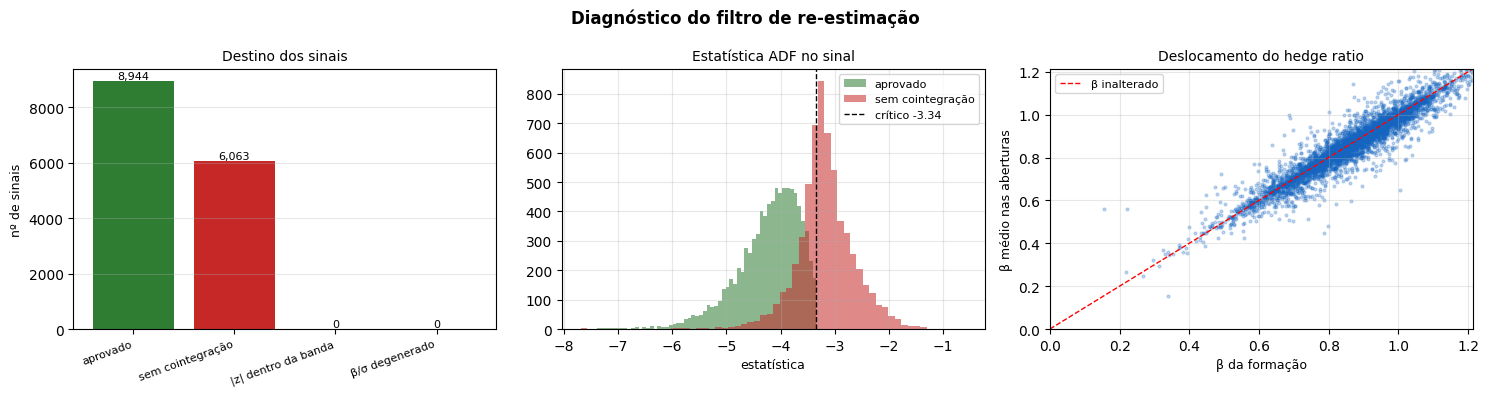

In [24]:
if len(eventos_df):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    fig.suptitle("Diagnóstico do filtro de re-estimação", fontsize=12, fontweight='bold')

    # 1) Destino dos sinais
    ordem  = ['aprovado', 'sem_cointegracao', 'z_reestimado_dentro_da_banda', 'beta_ou_sigma']
    rotulo = ['aprovado', 'sem cointegração', '|z| dentro da banda', 'β/σ degenerado']
    cores  = ['#2E7D32', '#C62828', '#EF6C00', '#616161']
    cont   = [(eventos_df['motivo'] == m).sum() for m in ordem]

    axes[0].bar(range(len(ordem)), cont, color=cores)
    axes[0].set_xticks(range(len(ordem)))
    axes[0].set_xticklabels(rotulo, rotation=20, ha='right', fontsize=8)
    axes[0].set_title("Destino dos sinais", fontsize=10)
    axes[0].set_ylabel("nº de sinais", fontsize=9)
    for i, v in enumerate(cont):
        axes[0].text(i, v, f"{v:,}", ha='center', va='bottom', fontsize=8)
    axes[0].grid(alpha=0.3, axis='y')

    # 2) Estatística do teste no sinal — aprovados × vetados por cointegração
    ax = axes[1]
    for m, cor, lbl in [('aprovado', '#2E7D32', 'aprovado'),
                        ('sem_cointegracao', '#C62828', 'sem cointegração')]:
        s = eventos_df.loc[eventos_df['motivo'] == m, 'stat_novo'].dropna()
        if len(s):
            ax.hist(s, bins=60, alpha=0.55, color=cor, label=lbl)
    if METODO_COINT_RETESTE == 'ADF':
        ax.axvline(CRIT_COINT_5PCT, color='black', ls='--', lw=1,
                   label=f'crítico {CRIT_COINT_5PCT}')
    ax.set_title(f"Estatística {METODO_COINT_RETESTE} no sinal", fontsize=10)
    ax.set_xlabel("estatística", fontsize=9)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

    # 3) β re-estimado × β da formação
    ax = axes[2]
    cb = resultados_df.dropna(subset=['beta_medio'])
    if len(cb):
        ax.scatter(cb['beta'], cb['beta_medio'], s=4, alpha=0.25, color='#1565C0')
        lim = [0, float(min(3, max(cb['beta'].quantile(0.99),
                                   cb['beta_medio'].quantile(0.99))))]
        ax.plot(lim, lim, color='red', ls='--', lw=1, label='β inalterado')
        ax.set_xlim(lim); ax.set_ylim(lim)
        ax.legend(fontsize=8)
    ax.set_xlabel("β da formação", fontsize=9)
    ax.set_ylabel("β médio nas aberturas", fontsize=9)
    ax.set_title("Deslocamento do hedge ratio", fontsize=10)
    ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

In [25]:
# Diagnóstico: quais pares foram pulados por dados ausentes e por qual motivo
if len(sem_dados_df) == 0:
    print("Nenhum par pulado por dados ausentes.")
else:
    def diagnostico(row):
        if row['dias_form_bruto'] == 0:
            return 'form_fora_do_range'
        if row['dias_neg_bruto'] == 0:
            return 'neg_fora_do_range'
        if row['dias_form_ok'] == 0:
            culpado = []
            if row['nan_form_a1'] == row['dias_form_bruto']: culpado.append(row['ativo1'])
            if row['nan_form_a2'] == row['dias_form_bruto']: culpado.append(row['ativo2'])
            return f"form_tudo_NaN: {'+'.join(culpado) or 'ambos'}"
        if row['dias_neg_ok'] == 0:
            culpado = []
            if row['nan_neg_a1'] == row['dias_neg_bruto']: culpado.append(row['ativo1'])
            if row['nan_neg_a2'] == row['dias_neg_bruto']: culpado.append(row['ativo2'])
            return f"neg_tudo_NaN: {'+'.join(culpado) or 'ambos'}"
        return 'parcial_dropna'

    sem_dados_df['motivo'] = sem_dados_df.apply(diagnostico, axis=1)

    display(
        sem_dados_df[['ativo1', 'ativo2', 'janela', 'neg_inicio',
                       'dias_neg_bruto', 'dias_neg_ok', 'motivo']]
        .reset_index(drop=True)
    )

,ativo1,ativo2,janela,neg_inicio,dias_neg_bruto,dias_neg_ok,motivo
0,1581Q,CVX,1996-05_a_1997-04,1997-05,129,0,neg_tudo_NaN: 1581Q
1,SO,UEP,1997-01_a_1997-12,1998-01,124,0,neg_tudo_NaN: UEP
2,MRO,COC,2001-09_a_2002-08,2002-09,124,0,neg_tudo_NaN: COC


## 6. Resultado por par

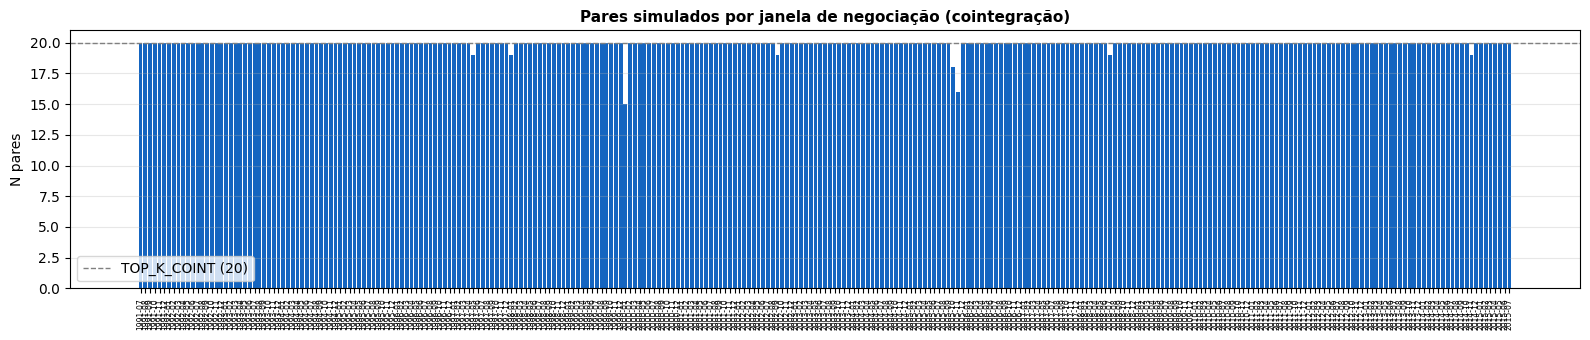

Janelas com 0 pares: 0
Média por janela   : 19.9
Mín / Máx          : 15 / 20


In [26]:
# Diagnóstico: pares simulados por janela de negociação
pares_por_janela = (
    resultados_df
    .groupby('neg_inicio')['ativo1']
    .count()
    .reset_index()
    .rename(columns={'ativo1': 'n_simulados'})
    .sort_values('neg_inicio')
)

fig, ax = plt.subplots(figsize=(16, 3.5))
cores = ['#1565C0' if n >= 10 else '#ef5350' for n in pares_por_janela['n_simulados']]
ax.bar(pares_por_janela['neg_inicio'], pares_por_janela['n_simulados'], color=cores)
ax.axhline(pares['rank'].max(), color='gray', lw=1.0, ls='--',
           label=f'TOP_K_COINT ({pares["rank"].max()})')
ax.set_title('Pares simulados por janela de negociação (cointegração)', fontsize=11, fontweight='bold')
ax.set_ylabel('N pares')
ax.tick_params(axis='x', rotation=90, labelsize=5.5)
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Janelas com 0 pares: {(pares_por_janela['n_simulados'] == 0).sum()}")
print(f"Média por janela   : {pares_por_janela['n_simulados'].mean():.1f}")
print(f"Mín / Máx          : {pares_por_janela['n_simulados'].min()} / {pares_por_janela['n_simulados'].max()}")

In [27]:
pares_com_trade = resultados_df[resultados_df['n_trades'] > 0]

print("=== Estatísticas de trades ===")
print(f"Pares que abriram ≥ 1 trade    : {len(pares_com_trade):,} de {len(resultados_df):,}")
print(f"Total de trades abertos        : {resultados_df['n_trades'].sum():,}")
print(f"Trades fechados normalmente    : {resultados_df['n_fechados'].sum():,}")
print(f"Trades forçados (fim período)  : {resultados_df['n_forcados'].sum():,}")

if resultados_df['n_trades'].sum() > 0:
    taxa_convergencia = resultados_df['n_fechados'].sum() / resultados_df['n_trades'].sum()
    print(f"\nTaxa de convergência           : {taxa_convergencia:.1%}")

print("\n=== Retorno por par ===")
print(resultados_df['retorno_total'].describe().to_string())

=== Estatísticas de trades ===
Pares que abriram ≥ 1 trade    : 5,036 de 5,764
Total de trades abertos        : 8,944
Trades fechados normalmente    : 5,356
Trades forçados (fim período)  : 3,588

Taxa de convergência           : 59.9%

=== Retorno por par ===
count    5764.000000
mean        0.015357
std         0.140682
min        -1.250316
25%        -0.042900
50%         0.009672
75%         0.086337
max         0.770998


In [28]:
print("Top 10 pares por retorno total:")
display(
    resultados_df
    .nlargest(10, 'retorno_total')
    [['neg_inicio', 'ativo1', 'ativo2', 'rank', 'beta', 'n_trades', 'n_fechados', 'retorno_total']]
    .reset_index(drop=True)
)

print("\nBottom 10 pares por retorno total:")
display(
    resultados_df
    .nsmallest(10, 'retorno_total')
    [['neg_inicio', 'ativo1', 'ativo2', 'rank', 'beta', 'n_trades', 'n_fechados', 'retorno_total']]
    .reset_index(drop=True)
)

Top 10 pares por retorno total:


,neg_inicio,ativo1,ativo2,rank,beta,n_trades,n_fechados,retorno_total
0,1997-03,GE,PFE,20,0.989373,7,7,0.770998
1,1996-01,SAF,RAL,18,0.885897,7,7,0.740530
2,1998-12,WFC,3253Q,14,0.787474,7,6,0.632814
3,1995-12,SAF,RAL,18,0.916126,5,5,0.615180
4,1999-10,FNMA,BNI,9,0.599685,4,4,0.606250
5,1998-03,AIG,AON,12,0.896331,8,7,0.593501
6,2000-06,0948669D,329556Q,3,0.981105,4,4,0.566792
7,2007-09,IFF,2968900Q,17,0.867759,6,6,0.545192
8,1997-01,896661Q,PAS,20,0.591452,5,4,0.541519
9,1997-12,UNM,ALL,8,0.919418,6,5,0.535436



Bottom 10 pares por retorno total:


,neg_inicio,ativo1,ativo2,rank,beta,n_trades,n_fechados,retorno_total
0,2012-10,TE,HRL,14,0.329171,1,0,-1.250316
1,2001-04,FMC,MCO,16,0.783560,1,0,-0.920257
2,1996-07,236555Q,1958Q,15,0.789925,1,0,-0.775088
3,2000-04,987200Q,NEE,20,0.736513,1,0,-0.762171
4,2000-07,IFF,FMCC,7,0.855004,1,0,-0.725064
5,1998-01,BNI,2251Q,11,0.796104,1,0,-0.701431
6,2010-12,TAP,MRO,18,0.817638,1,0,-0.693904
7,1997-11,LB,DDS,6,0.907250,1,0,-0.663239
8,1997-12,BNI,2251Q,19,0.787861,1,0,-0.629168
9,2000-08,3022239Q,GRA,13,0.837613,1,0,-0.614971


## 7. Portfólio e curva de equity (série diária)

O retorno diário do portfólio é a **média dos retornos de todos os pares** na convenção escolhida:

- **`COMMITTED_CAPITAL = True`** (Rad et al., 2016): todos os N pares entram no denominador todos os dias. Pares sem posição contribuem 0.
- **`COMMITTED_CAPITAL = False`** ("fully invested"): apenas pares com posição ativa entram na média.

> Esta série diária junta num único pool os pares de **todas** as janelas sobrepostas ativas
> no dia. É útil para a curva de equity e para métricas de risco de alta frequência, mas
> **não é a medida do artigo**: Rad et al. reportam retornos **mensais**, calculados por
> portfólio e depois agregados. Essas medidas (REC e RCC) estão na seção 8.

In [29]:
portfolio = pd.Series(
    {date: np.mean(rets) for date, rets in retornos_por_data.items()}
).sort_index()

equity = (1 + portfolio).cumprod()

print(f"Período do portfólio: {portfolio.index[0].date()} → {portfolio.index[-1].date()}")
print(f"Dias de negociação  : {len(portfolio):,}")
print(f"Retorno diário médio: {portfolio.mean():.4%}")
print(f"Retorno acumulado   : {equity.iloc[-1] - 1:.2%}")

Período do portfólio: 1991-07-01 → 2015-12-31
Dias de negociação  : 6,174
Retorno diário médio: 0.0122%
Retorno acumulado   : 109.79%


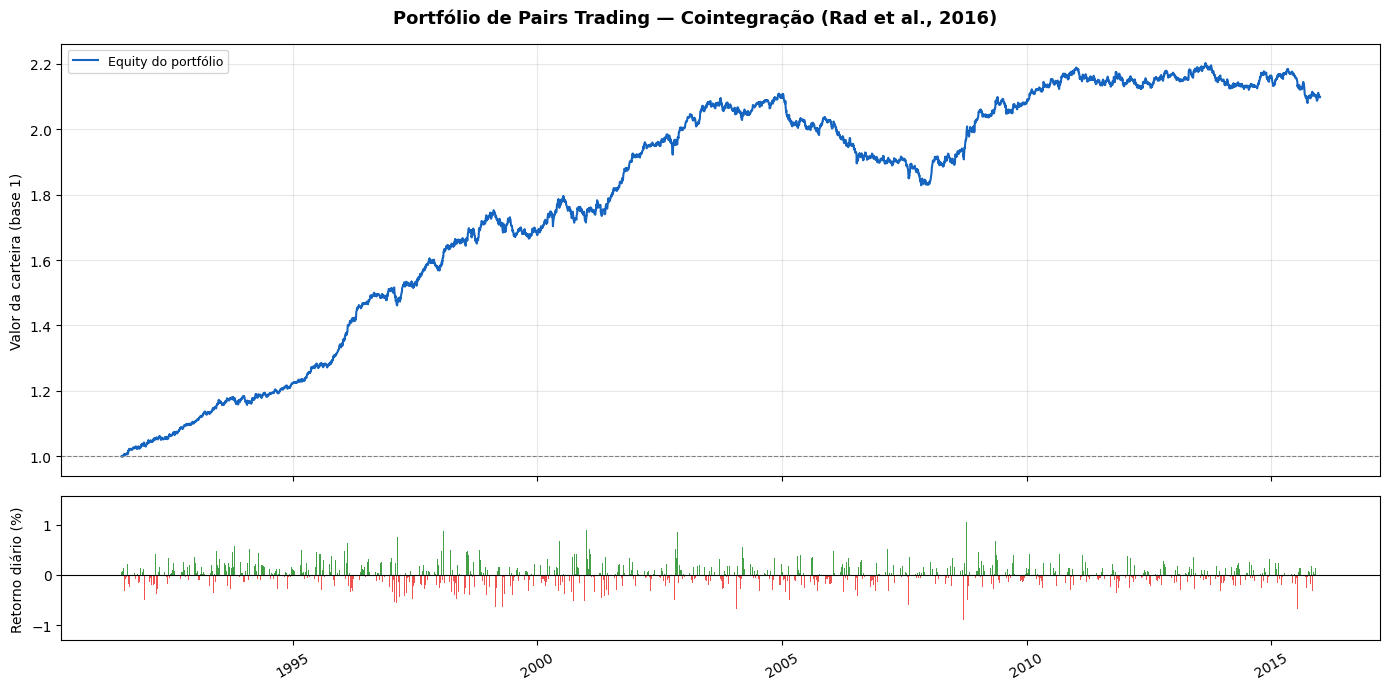

In [30]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True,
                          gridspec_kw={'height_ratios': [3, 1]})
fig.suptitle("Portfólio de Pairs Trading — Cointegração (Rad et al., 2016)",
             fontsize=13, fontweight='bold')

ax_eq = axes[0]
ax_eq.plot(equity.index, equity.values, color='#1565C0', lw=1.5, label='Equity do portfólio')
ax_eq.axhline(1, color='gray', lw=0.8, ls='--')
ax_eq.set_ylabel('Valor da carteira (base 1)', fontsize=10)
ax_eq.legend(fontsize=9)
ax_eq.grid(alpha=0.3)

ax_ret = axes[1]
colors = ['#ef5350' if r < 0 else '#43A047' for r in portfolio.values]
ax_ret.bar(portfolio.index, portfolio.values * 100, color=colors, width=1)
ax_ret.axhline(0, color='black', lw=0.8)
ax_ret.set_ylabel('Retorno diário (%)', fontsize=10)
ax_ret.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax_ret.xaxis.set_major_locator(mdates.YearLocator(5))
ax_ret.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

## 8. Retorno mensal — REC e RCC (Rad et al., §4.5)

O artigo reporta o desempenho em **retornos mensais**, com duas medidas calculadas
**separadamente para cada portfólio** (cada janela de formação/negociação) e só depois
agregadas:

$$R^{EC}_m = \frac{\sum_{i=1}^{n} r_i}{n} \qquad (14) \qquad\qquad R^{CC}_m = \frac{\sum_{i=1}^{n} r_i}{N_P},\quad N_P = 20 \qquad (15)$$

onde $r_i$ é o retorno marcado a mercado do par $i$ no mês $m$ e $n$ é o número de pares que
**efetivamente negociaram** naquele mês dentro daquele portfólio.

- **REC** (*return on employed capital*) ignora o capital parado — é a medida usada como
  referência ao longo do artigo (os 85 bps antes de custos).
- **RCC** (*return on committed capital*) divide sempre pelos $N_P = 20$ pares nominados,
  tenham negociado ou não. É a medida conservadora, que "imita o que um hedge fund reportaria",
  pois considera o custo de oportunidade do capital alocado e não usado.

O retorno mensal da estratégia é a **média equiponderada dos portfólios sobrepostos ativos
naquele mês** (§4.5) — no máximo seis, já que a negociação dura 6 meses e uma nova janela
começa a cada mês.

> Meses em que um portfólio não abriu nenhum trade têm REC indefinido (0/0) e são omitidos da
> média daquele mês; para o RCC contam como 0, porque o capital seguiu comprometido.
>
> `r_i` é a **soma** dos P&L diários do par no mês, não o produto composto: cada dia é um P&L
> em dólares sobre uma posição comprada de \$1 fixa (não reinvestida), e portanto aditivo.

In [31]:
# ── REC e RCC mensais: primeiro por portfólio (janela), depois média dos sobrepostos ──────
# Um "portfólio" é uma janela de formação/negociação. A cada mês há até 6 portfólios ativos
# ao mesmo tempo, e o retorno do mês é a média equiponderada deles (Rad et al., §4.5).

todos_pm = mensal_df.groupby(['janela', 'mes']).size().rename('n_pares')   # todo portfólio-mês
negoc    = mensal_df[mensal_df['negociou']]                                # só quem negociou

soma_r = (negoc.groupby(['janela', 'mes'])['r_mes'].sum()
               .reindex(todos_pm.index, fill_value=0.0))
n_neg  = (negoc.groupby(['janela', 'mes'])['r_mes'].size()
               .reindex(todos_pm.index, fill_value=0))

port_mes = pd.DataFrame({
    'n_pares':      todos_pm,                        # pares simulados nesse portfólio
    'n_negociaram': n_neg,                           # n da eq. (14)
    'soma_r':       soma_r,                          # Σ r_i
    'REC':          soma_r / n_neg.where(n_neg > 0), # eq. (14); n = 0 → NaN (mês sem trade)
    'RCC':          soma_r / N_PARES_NOMINADOS,      # eq. (15), N_P fixo = 20
}).reset_index()

# Média equiponderada dos portfólios sobrepostos ativos em cada mês
rec_mensal = port_mes.groupby('mes')['REC'].mean()   # NaN (portfólio sem trade) é ignorado
rcc_mensal = port_mes.groupby('mes')['RCC'].mean()

n_por_mes = port_mes.groupby('mes').size()

print(f"Portfólios (janelas)             : {port_mes['janela'].nunique():,}")
print(f"Observações portfólio-mês        : {len(port_mes):,}")
print(f"Meses de calendário              : {port_mes['mes'].nunique():,} "
      f"({port_mes['mes'].min()} → {port_mes['mes'].max()})")
print(f"Portfólios sobrepostos por mês   : média {n_por_mes.mean():.2f} | máx {n_por_mes.max()}")
print(f"Portfólio-mês sem nenhum trade   : {(port_mes['n_negociaram'] == 0).sum():,} "
      f"({(port_mes['n_negociaram'] == 0).mean():.1%})  → REC indefinido, RCC = 0")
print(f"Pares que negociaram por mês     : média {port_mes['n_negociaram'].mean():.1f} "
      f"de {N_PARES_NOMINADOS} nominados "
      f"(pares simulados por portfólio: média {port_mes['n_pares'].mean():.1f})")
print(f"Meses sem REC (nenhum portfólio negociou): {rec_mensal.isna().sum():,}")

Portfólios (janelas)             : 289
Observações portfólio-mês        : 1,734
Meses de calendário              : 294 (1991-07 → 2015-12)
Portfólios sobrepostos por mês   : média 5.90 | máx 6
Portfólio-mês sem nenhum trade   : 0 (0.0%)  → REC indefinido, RCC = 0
Pares que negociaram por mês     : média 13.6 de 20 nominados (pares simulados por portfólio: média 19.8)
Meses sem REC (nenhum portfólio negociou): 0


In [32]:
# ── Distribuição dos retornos mensais, no formato da Tabela 3 de Rad et al. ───────────────
def estatisticas_mensais(serie, nome):
    """Estatísticas de uma série de retornos MENSAIS (mesmas colunas da Tabela 3 do artigo)."""
    s     = serie.dropna()
    n     = len(s)
    media = s.mean()
    dp    = s.std(ddof=1)
    return {
        'Medida':          nome,
        'N meses':         n,
        'Média':           media,
        't-stat':          media / (dp / np.sqrt(n)),
        'Desvio-padrão':   dp,
        'Sharpe (mensal)': media / dp,
        'Assimetria':      s.skew(),
        'Curtose':         s.kurtosis() + 3,   # pandas devolve curtose EXCEDENTE; Rad reporta a bruta
    }


tabela_mensal = pd.DataFrame([
    estatisticas_mensais(rec_mensal, 'REC — capital empregado'),
    estatisticas_mensais(rcc_mensal, 'RCC — capital comprometido'),
]).set_index('Medida')

# Referência: Rad et al. (2016), Tabela 3, cointegração, ANTES de custos, CRSP 1962-2014.
# Amostra e universo diferentes dos nossos — serve como ordem de grandeza, não como alvo exato.
tabela_rad = pd.DataFrame([
    {'Medida': 'REC — Rad et al. (antes de custos)', 'N meses': 630, 'Média': 0.0085,
     't-stat': 7.3268, 'Desvio-padrão': 0.0111, 'Sharpe (mensal)': 0.7703,
     'Assimetria': 0.8130, 'Curtose': 7.3561},
    {'Medida': 'RCC — Rad et al. (antes de custos)', 'N meses': 630, 'Média': 0.0068,
     't-stat': 7.0365, 'Desvio-padrão': 0.0097, 'Sharpe (mensal)': 0.6969,
     'Assimetria': 1.3934, 'Curtose': 10.8547},
]).set_index('Medida')

comparativo = pd.concat([tabela_mensal, tabela_rad])

print("=" * 78)
print("  RETORNO MENSAL — média dos portfólios sobrepostos (Rad et al., eq. 14 e 15)")
print(f"  {rec_mensal.index.min()} → {rec_mensal.index.max()}  |  SEM custos de transação")
print("=" * 78)

fmt = {'N meses': '{:.0f}', 'Média': '{:.4f}', 't-stat': '{:.4f}', 'Desvio-padrão': '{:.4f}',
       'Sharpe (mensal)': '{:.4f}', 'Assimetria': '{:.4f}', 'Curtose': '{:.4f}'}
display(comparativo.style.format(fmt))

print(f"\nREC — média mensal: {tabela_mensal.loc['REC — capital empregado', 'Média']:.2%} "
      f"| meses positivos: {(rec_mensal.dropna() > 0).mean():.1%}")
print(f"RCC — média mensal: {tabela_mensal.loc['RCC — capital comprometido', 'Média']:.2%} "
      f"| meses positivos: {(rcc_mensal.dropna() > 0).mean():.1%}")

  RETORNO MENSAL — média dos portfólios sobrepostos (Rad et al., eq. 14 e 15)
  1991-07 → 2015-12  |  SEM custos de transação


,N meses,Média,t-stat,Desvio-padrão,Sharpe (mensal),Assimetria,Curtose
Medida,,,,,,,
REC — capital empregado,294,0.0037,4.3188,0.0147,0.2519,0.2377,3.4844
RCC — capital comprometido,294,0.0026,4.3931,0.0100,0.2562,0.3049,3.5474
REC — Rad et al. (antes de custos),630,0.0085,7.3268,0.0111,0.7703,0.8130,7.3561
RCC — Rad et al. (antes de custos),630,0.0068,7.0365,0.0097,0.6969,1.3934,10.8547



REC — média mensal: 0.37% | meses positivos: 59.9%
RCC — média mensal: 0.26% | meses positivos: 59.9%


## 9. Métricas de performance (série diária)

In [33]:
sharpe             = portfolio.mean() / portfolio.std() * np.sqrt(252)
rolling_max        = equity.cummax()
drawdown           = (equity - rolling_max) / rolling_max
max_dd             = drawdown.min()
n_anos             = len(portfolio) / 252
retorno_anualizado = equity.iloc[-1] ** (1 / n_anos) - 1
dias_positivos     = (portfolio > 0).mean()

print("=" * 40)
print("     MÉTRICAS DE PERFORMANCE")
print("=" * 40)
print(f"Retorno acumulado      : {equity.iloc[-1] - 1:>+.2%}")
print(f"Retorno anualizado     : {retorno_anualizado:>+.2%}")
print(f"Volatilidade anual     : {portfolio.std() * np.sqrt(252):>.2%}")
print(f"Sharpe ratio           : {sharpe:>+.2f}")
print(f"Drawdown máximo        : {max_dd:>+.2%}")
print(f"Dias com retorno > 0   : {dias_positivos:.1%}")
print("=" * 40)

     MÉTRICAS DE PERFORMANCE
Retorno acumulado      : +109.79%
Retorno anualizado     : +3.07%
Volatilidade anual     : 3.23%
Sharpe ratio           : +0.95
Drawdown máximo        : -13.31%
Dias com retorno > 0   : 51.9%


### 9.1 Retorno bruto × retorno líquido de renda fixa

As mesmas métricas acima, calculadas sobre **duas séries**:

- **bruto** — $r_p(t)$, o retorno do portfólio exatamente como calculado na célula anterior
- **líquido** — $r_p(t) - r_f(t)$, subtraindo a taxa livre de risco diária

A taxa vem de `rf_diario.csv` (Rf do professor até 2015-12-30 + T-bill de 3 meses do FRED de 2016 em diante), gerado por [`serie_rf.ipynb`](../database_formation/serie_rf.ipynb).

In [34]:
# ── Retorno bruto × retorno líquido de renda fixa ─────────────────────────────
PATH_RF = '../../data_bases/rf_diario.csv'

rf = pd.read_csv(PATH_RF, parse_dates=['date']).set_index('date')['rf']
rf = rf.reindex(portfolio.index)

if rf.isna().any():
    print(f"⚠ {rf.isna().sum()} dia(s) do portfólio sem taxa — preenchidos com o último valor disponível.\n")
    rf = rf.ffill().bfill()

portfolio_liquido = portfolio - rf


def metricas_performance(serie):
    """Métricas anualizadas de uma série de retornos diários."""
    equity  = (1 + serie).cumprod()
    maxacum = equity.cummax()
    n_anos  = len(serie) / 252
    return {
        'Retorno acumulado'    : equity.iloc[-1] - 1,
        'Retorno anualizado'   : equity.iloc[-1] ** (1 / n_anos) - 1,
        'Média diária × 252'   : serie.mean() * 252,
        'Volatilidade anual'   : serie.std() * np.sqrt(252),
        'Sharpe ratio'         : serie.mean() / serie.std() * np.sqrt(252),
        'Drawdown máximo'      : ((equity - maxacum) / maxacum).min(),
        'Dias com retorno > 0' : (serie > 0).mean(),
    }


bruto   = metricas_performance(portfolio)
liquido = metricas_performance(portfolio_liquido)

rf_aa = (1 + rf.mean()) ** 252 - 1
print(f"Renda fixa no período : {rf_aa:.2%} a.a. (média diária de {rf.mean():.6f})")
print(f"Período               : {portfolio.index[0].date()} → {portfolio.index[-1].date()}  "
      f"({len(portfolio):,} dias)")
print()

print("=" * 66)
print("   MÉTRICAS DE PERFORMANCE — bruto × líquido de renda fixa")
print("=" * 66)
print(f"{'':<24}{'bruto':>13}{'líquido':>13}{'diferença':>14}")
print("-" * 66)
SEM_SINAL = {'Volatilidade anual', 'Dias com retorno > 0'}
for nome in bruto:
    b, l, d = bruto[nome], liquido[nome], liquido[nome] - bruto[nome]
    if nome == 'Sharpe ratio':
        print(f"{nome:<24}{b:>13.2f}{l:>13.2f}{d:>+14.2f}")
    elif nome in SEM_SINAL:
        print(f"{nome:<24}{b:>13.2%}{l:>13.2%}{d:>+14.2%}")
    else:
        print(f"{nome:<24}{b:>+13.2%}{l:>+13.2%}{d:>+14.2%}")
print("=" * 66)

⚠ 1 dia(s) do portfólio sem taxa — preenchidos com o último valor disponível.

Renda fixa no período : 2.65% a.a. (média diária de 0.000104)
Período               : 1991-07-01 → 2015-12-31  (6,174 dias)

   MÉTRICAS DE PERFORMANCE — bruto × líquido de renda fixa
                                bruto      líquido     diferença
------------------------------------------------------------------
Retorno acumulado            +109.79%      +10.41%       -99.38%
Retorno anualizado             +3.07%       +0.41%        -2.67%
Média diária × 252             +3.08%       +0.46%        -2.62%
Volatilidade anual              3.23%        3.23%        -0.00%
Sharpe ratio                     0.95         0.14         -0.81
Drawdown máximo               -13.31%      -23.70%       -10.39%
Dias com retorno > 0           51.90%       49.69%        -2.20%


Meses positivos: 176 de 294  (60%)


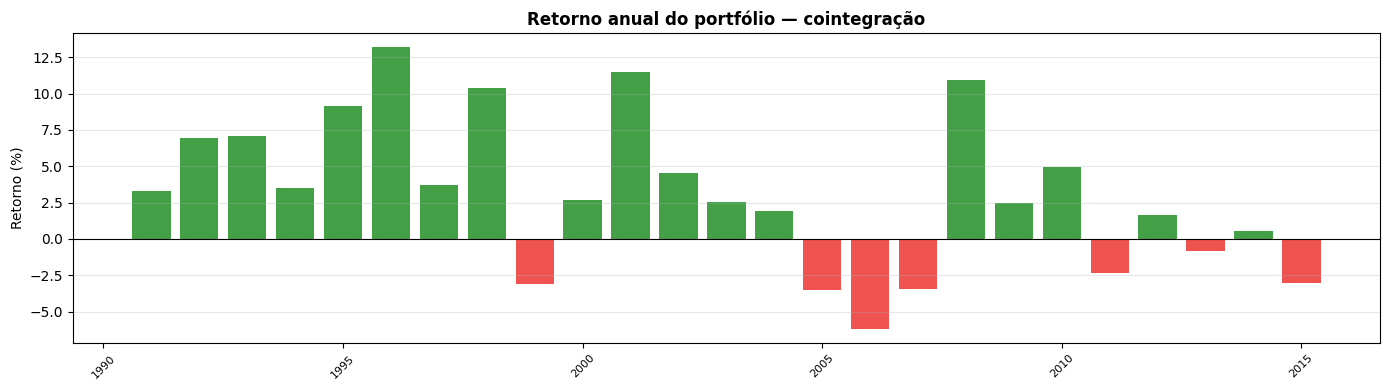

In [35]:
# Retorno por mês de negociação
port_df = portfolio.to_frame('retorno')
port_df['ano'] = port_df.index.year
port_df['mes'] = port_df.index.month
port_df['ano_mes'] = port_df.index.to_period('M').astype(str)

retorno_mensal = (
    port_df.groupby('ano_mes')['retorno']
    .apply(lambda r: (1 + r).prod() - 1)
    .reset_index()
    .rename(columns={'retorno': 'retorno_mensal'})
)

print(f"Meses positivos: {(retorno_mensal['retorno_mensal'] > 0).sum()} "
      f"de {len(retorno_mensal)}  ({(retorno_mensal['retorno_mensal'] > 0).mean():.0%})")

# Agrega por ano para o gráfico (menos poluído)
retorno_anual = (
    port_df.groupby('ano')['retorno']
    .apply(lambda r: (1 + r).prod() - 1)
    .reset_index()
    .rename(columns={'retorno': 'retorno_anual'})
)

fig, ax = plt.subplots(figsize=(14, 4))
cores = ['#43A047' if r > 0 else '#ef5350' for r in retorno_anual['retorno_anual']]
ax.bar(retorno_anual['ano'], retorno_anual['retorno_anual'] * 100, color=cores)
ax.axhline(0, color='black', lw=0.8)
ax.set_title('Retorno anual do portfólio — cointegração', fontsize=12, fontweight='bold')
ax.set_ylabel('Retorno (%)')
ax.tick_params(axis='x', rotation=45, labelsize=8)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

## 10. Comparação — estático × dinâmico

Confronta esta simulação com a do notebook `pairs_trading_coint.ipynb`, lendo os CSVs que ele
gravou. **Pré-requisito:** os dois notebooks precisam ter rodado sobre o mesmo
`pares_formados_coint.csv` e o mesmo intervalo de datas — caso contrário a comparação não é
pareada e as métricas não são confrontáveis.

In [36]:
import os

PATH_BASE_PORT = 'output/resultados/negociacao_portfolio_coint.csv'
PATH_BASE_PAR  = 'output/resultados/negociacao_pares_coint.csv'

if not os.path.exists(PATH_BASE_PORT):
    print(f"Baseline estático não encontrado em {PATH_BASE_PORT}.")
    print("Rode pairs_trading_coint.ipynb primeiro para gerar a comparação.")
else:
    base_port = (pd.read_csv(PATH_BASE_PORT, parse_dates=['date'])
                   .set_index('date')['retorno_diario'])
    base_par  = pd.read_csv(PATH_BASE_PAR)

    # Datas em comum — garante que as métricas comparem o mesmo período
    idx = portfolio.index.intersection(base_port.index)
    est = base_port.reindex(idx)
    din = portfolio.reindex(idx)

    if len(idx) < len(portfolio) or len(idx) < len(base_port):
        print(f"⚠️  Períodos diferem: dinâmico {len(portfolio):,} dias, "
              f"estático {len(base_port):,} dias → comparando {len(idx):,} dias em comum.\n")

    def metricas(s):
        eq = (1 + s).cumprod()
        dd = (eq - eq.cummax()) / eq.cummax()
        return {
            'Retorno acumulado' : eq.iloc[-1] - 1,
            'Retorno anualizado': eq.iloc[-1] ** (252 / len(s)) - 1,
            'Volatilidade anual': s.std() * np.sqrt(252),
            'Sharpe ratio'      : s.mean() / s.std() * np.sqrt(252),
            'Drawdown máximo'   : dd.min(),
            'Dias positivos'    : (s > 0).mean(),
        }

    m_est, m_din = metricas(est), metricas(din)

    print("=" * 74)
    print("   PORTFÓLIO — ESTÁTICO × DINÂMICO   (mesmas datas, sem custos)")
    print("=" * 74)
    print(f"{'':<22}{'estático':>16}{'dinâmico':>16}{'diferença':>16}")
    print("-" * 74)
    for k in m_est:
        a, b = m_est[k], m_din[k]
        if k == 'Sharpe ratio':
            print(f"{k:<22}{a:>16.2f}{b:>16.2f}{b - a:>+16.2f}")
        else:
            print(f"{k:<22}{a:>15.2%}{b:>16.2%}{b - a:>+16.2%}")
    print("=" * 74)

    # ── Trades ────────────────────────────────────────────────────────────────────
    def conv(d):
        tot = d['n_trades'].sum()
        return d['n_fechados'].sum() / tot if tot else np.nan

    print(f"\n{'':<28}{'estático':>14}{'dinâmico':>14}")
    print("-" * 56)
    print(f"{'Trades abertos':<28}{base_par['n_trades'].sum():>14,}"
          f"{resultados_df['n_trades'].sum():>14,}")
    print(f"{'Fechados por reversão':<28}{base_par['n_fechados'].sum():>14,}"
          f"{resultados_df['n_fechados'].sum():>14,}")
    print(f"{'Forçados (fim do período)':<28}{base_par['n_forcados'].sum():>14,}"
          f"{resultados_df['n_forcados'].sum():>14,}")
    print(f"{'Taxa de convergência':<28}{conv(base_par):>13.1%}{conv(resultados_df):>14.1%}")
    print(f"{'Retorno médio por par':<28}{base_par['retorno_total'].mean():>13.2%}"
          f"{resultados_df['retorno_total'].mean():>14.2%}")
    print(f"{'Sinais avaliados':<28}{'—':>14}{resultados_df['n_sinais'].sum():>14,}")
    print("\nNota: 'sinais avaliados' não tem contrapartida no estático — lá todo sinal vira")
    print("trade. As duas contagens não são pareáveis (ver cabeçalho): vetos devolvem o par ao")
    print("monitoramento e elevam os sinais; trades mais longos engolem cruzamentos e os reduzem.")

    # ── Curvas de equity e drawdown ───────────────────────────────────────────────
    eq_est, eq_din = (1 + est).cumprod(), (1 + din).cumprod()
    dd_est = (eq_est - eq_est.cummax()) / eq_est.cummax()
    dd_din = (eq_din - eq_din.cummax()) / eq_din.cummax()

    fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True,
                             gridspec_kw={'height_ratios': [3, 1]})
    fig.suptitle("Cointegração — estático × dinâmico (re-estimação no sinal)",
                 fontsize=12, fontweight='bold')

    ax = axes[0]
    ax.plot(eq_est.index, eq_est.values, color='#90A4AE', lw=1.4, label='estático')
    ax.plot(eq_din.index, eq_din.values, color='#1565C0', lw=1.6, label='dinâmico')
    ax.set_ylabel("Equity (base 1)", fontsize=9)
    ax.set_yscale('log')
    ax.legend(fontsize=9)
    ax.grid(alpha=0.3, which='both')

    ax = axes[1]
    ax.fill_between(dd_est.index, dd_est.values, 0, color='#90A4AE', alpha=0.6, label='estático')
    ax.fill_between(dd_din.index, dd_din.values, 0, color='#1565C0', alpha=0.5, label='dinâmico')
    ax.set_ylabel("Drawdown", fontsize=9)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

ValueError: Missing column provided to 'parse_dates': 'date'

## 11. Explorando um par específico

Altere as variáveis abaixo para visualizar qualquer par em qualquer janela. O gráfico mostra os
**dois** z-scores lado a lado — o de monitoramento (parâmetros da formação, que dispara o
sinal) e o do trade vigente (parâmetros re-estimados, que governa o fechamento) — marcando
cada sinal aprovado (○) e cada sinal vetado pelo re-teste (✕).

In [ ]:
# === Configuração: escolha o par a explorar ===
NEG_INICIO_ALVO = resultados_df['neg_inicio'].iloc[0]  # primeiro período disponível
RANK_ALVO       = 1

par_info = pares[
    (pares['negociacao_inicio'] == NEG_INICIO_ALVO) &
    (pares['rank'] == RANK_ALVO)
].squeeze()

metodo_lbl = par_info['metodo'] if 'metodo' in par_info.index else 'stat'
print(f"Par selecionado    : {par_info['ativo1']} / {par_info['ativo2']}")
print(f"Janela             : {par_info['janela']}")
print(f"Negociação         : {par_info['negociacao_inicio']} → {par_info['negociacao_fim']}")
print(f"Direção (OLS)      : {par_info['direcao']}")
print(f"Beta (formação)    : {par_info['beta']:.4f}")
print(f"Alpha (formação)   : {par_info['alpha']:.4f}")
print(f"Estatística ({metodo_lbl}) : {par_info['stat']:.4f}")
print(f"Spread μ           : {par_info['spread_media']:.6f}")
print(f"Spread σ           : {par_info['spread_desvio']:.6f}")

In [ ]:
a1 = par_info['ativo1']
a2 = par_info['ativo2']

form_inicio = pd.Period(par_info['formacao_inicio'],   freq='M')
form_fim    = pd.Period(par_info['formacao_fim'],      freq='M')
neg_inicio  = pd.Period(par_info['negociacao_inicio'], freq='M')
neg_fim     = pd.Period(par_info['negociacao_fim'],    freq='M')

mask_form = (meses_por_linha >= form_inicio) & (meses_por_linha <= form_fim)
mask_neg  = (meses_por_linha >= neg_inicio)  & (meses_por_linha <= neg_fim)

precos_form = df.loc[mask_form, [a1, a2]].dropna()
precos_neg  = df.loc[mask_neg,  [a1, a2]].dropna()

resultado, info = simular_par_coint_dinamico(
    precos_form, precos_neg,
    par_info['alpha'], par_info['beta'],
    par_info['spread_media'], par_info['spread_desvio'],
    direcao=par_info['direcao']
)

if resultado is None:
    print("Par não pode ser simulado.")
else:
    n_ab, n_fec, n_for = contar_trades(resultado['position'].values)
    print(f"Sinais gerados   : {info['n_sinais']}")
    print(f"  aprovados      : {info['n_aprovados']}")
    print(f"  sem coint.     : {info['n_rej_coint']}")
    print(f"  |z| na banda   : {info['n_rej_z']}")
    print(f"  β/σ degenerado : {info['n_rej_beta']}")
    print(f"Trades abertos   : {n_ab}")
    print(f"Fechados (z→0)   : {n_fec}")
    print(f"Forçados         : {n_for}")
    print(f"β médio aberturas: "
          f"{info['beta_medio']:.4f}" if np.isfinite(info['beta_medio']) else "β médio aberturas: —")
    print(f"Retorno total    : {resultado['retorno_diario'].sum():+.4%}")

    if info['eventos']:
        display(pd.DataFrame(info['eventos']))

In [ ]:
if resultado is not None:
    P0         = precos_form.sort_index().iloc[0]
    Q_neg      = precos_neg / P0
    equity_par = (1 + resultado['retorno_diario']).cumprod()

    dep, indep = (a1, a2) if par_info['direcao'] == 'A~B' else (a2, a1)
    metodo_lbl = par_info['metodo'] if 'metodo' in par_info.index else 'stat'

    fig, axes = plt.subplots(3, 1, figsize=(13, 9.5), sharex=True,
                             gridspec_kw={'height_ratios': [2, 2.2, 1]})
    fig.suptitle(
        f"{a1} / {a2} — negociação {par_info['negociacao_inicio']} → {par_info['negociacao_fim']}  "
        f"β_form={par_info['beta']:.3f}  {metodo_lbl}={par_info['stat']:.2f}  "
        f"[{par_info['direcao']}]  ·  DINÂMICO",
        fontsize=11, fontweight='bold'
    )

    # Painel 1: preços normalizados Q(t) no período de negociação
    ax1 = axes[0]
    ax1.plot(Q_neg.index, Q_neg[a1], color='#2196F3', lw=1.5, label=a1)
    ax1.plot(Q_neg.index, Q_neg[a2], color='#FF5722', lw=1.5, ls='--', label=a2)
    ax1.set_ylabel('Q(t) = P(t) / P₀_form', fontsize=9)
    ax1.legend(fontsize=9)
    ax1.grid(alpha=0.3)

    # Painel 2: z de monitoramento × z do trade + sinais vetados
    ax2 = axes[1]
    ax2.plot(resultado.index, resultado['z_monitor'], color='#9E9E9E', lw=1.1,
             label='z monitoramento (β,μ,σ da formação)')
    ax2.plot(resultado.index, resultado['z_trade'], color='purple', lw=1.6,
             label='z do trade (parâmetros re-estimados)')
    ax2.axhline(0,      color='black', lw=0.8)
    ax2.axhline(+DELTA, color='red',   lw=0.9, ls='--',
                label=f'+{DELTA}σ (long {indep} / short {dep})')
    ax2.axhline(-DELTA, color='green', lw=0.9, ls='--',
                label=f'-{DELTA}σ (long {dep} / short {indep})')
    if STOP is not None:
        ax2.axhline(+STOP, color='red',   lw=0.7, ls=':', alpha=0.5)
        ax2.axhline(-STOP, color='green', lw=0.7, ls=':', alpha=0.5)

    # Marca cada sinal avaliado: ○ aprovado, ✕ vetado
    for ev in info['eventos']:
        aprov = ev['motivo'] == 'aprovado'
        ax2.scatter(ev['data'], ev['z_monitor'],
                    marker='o' if aprov else 'x',
                    s=70 if aprov else 90,
                    facecolors='none' if aprov else '#C62828',
                    edgecolors='#2E7D32' if aprov else '#C62828',
                    linewidths=1.8, zorder=5)

    # Sombreia os dias posicionados
    pos_arr, datas = resultado['position'].values, resultado.index
    for t in range(len(pos_arr)):
        if pos_arr[t] != 0:
            cor = '#C8E6C9' if pos_arr[t] == +1 else '#FFCDD2'
            ax2.axvspan(datas[t], datas[min(t + 1, len(datas) - 1)], alpha=0.3, color=cor)

    ax2.set_ylabel('Z-score', fontsize=9)
    ax2.legend(fontsize=7.5, loc='upper right')
    ax2.grid(alpha=0.3)
    ax2.text(0.005, 0.03, "○ sinal aprovado     ✕ sinal vetado pelo re-teste",
             transform=ax2.transAxes, fontsize=8, color='#455A64')

    # Painel 3: equity acumulada do par
    ax3 = axes[2]
    ax3.plot(equity_par.index, equity_par.values, color='#1565C0', lw=1.5)
    ax3.axhline(1, color='gray', lw=0.8, ls='--')
    ax3.set_ylabel('Equity do par', fontsize=9)
    ax3.xaxis.set_major_formatter(mdates.DateFormatter('%b/%y'))
    ax3.tick_params(axis='x', rotation=30)
    ax3.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

## 11. Salvando resultados

In [ ]:
SUFIXO = '_coint_dinamico'

resultados_df.to_csv(f'output/resultados/negociacao_pares{SUFIXO}.csv', index=False)
portfolio.to_frame('retorno_diario').to_csv(f'output/resultados/negociacao_portfolio{SUFIXO}.csv')

# Retorno mensal no formato do artigo (Rad et al., §4.5)
port_mes.to_csv(f'output/resultados/negociacao_portfolio_mes{SUFIXO}.csv', index=False)
(pd.DataFrame({'REC': rec_mensal, 'RCC': rcc_mensal})
   .rename_axis('mes')
   .to_csv(f'output/resultados/negociacao_retorno_mensal{SUFIXO}.csv'))

# Log de todos os sinais avaliados — insumo da análise do filtro dinâmico
if len(eventos_df):
    eventos_df.to_csv(f'output/resultados/eventos_reteste{SUFIXO}.csv', index=False)

print("Salvo:")
print(f"  output/resultados/negociacao_pares{SUFIXO}.csv           — resultado por par (+ contadores de veto)")
print(f"  output/resultados/negociacao_portfolio{SUFIXO}.csv       — série diária do portfólio")
print(f"  output/resultados/negociacao_portfolio_mes{SUFIXO}.csv   — REC/RCC por portfólio-mês")
print(f"  output/resultados/negociacao_retorno_mensal{SUFIXO}.csv  — REC/RCC mensais agregados")
if len(eventos_df):
    print(f"  output/resultados/eventos_reteste{SUFIXO}.csv           — um registro por sinal avaliado")